# Data Visualization with t-SNE

This notebook implements the Data Visualization section of the project. The goal is to project the high-dimensional Student Dropout dataset into 2D and 3D using t-SNE, then inspect whether the target classes show visible local structure.

Important interpretation rule: t-SNE is mainly for local-neighborhood visualization. Cluster sizes and long-range distances between clusters should be interpreted cautiously.


## 1. Import Packages


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OneHotEncoder, StandardScaler

plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.family"] = "DejaVu Sans"
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
print("Libraries loaded successfully.")


Libraries loaded successfully.


## 2. Load Processed Data

The preprocessed dataset has numeric features and an encoded target column. The target mapping from preprocessing is:

- `0`: Dropout
- `1`: Enrolled
- `2`: Graduate


In [3]:
DATA_PATH = Path("dataset/processed_data.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("../dataset/processed_data.csv")

df = pd.read_csv(DATA_PATH)
df.columns = df.columns.str.strip()

target_map = {
    0: "Dropout",
    1: "Enrolled",
    2: "Graduate",
}

df["Target"] = df["Target"].astype(int)
df["Target Label"] = df["Target"].map(target_map)

print(f"Dataset shape: {df.shape}")
print("Target distribution:")
display(df["Target Label"].value_counts().rename_axis("Target").to_frame("Count"))
display(df.head())

Dataset shape: (4424, 38)
Target distribution:


,Count
Target,
Graduate,2209
Dropout,1421
Enrolled,794


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target,Target Label
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0.000000,0,10.8,1.4,1.74,0,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,6,6,6,13.666667,0,13.9,-0.3,0.79,2,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,6,0,0,0.000000,0,10.8,1.4,1.74,0,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,6,10,5,12.400000,0,9.4,-0.8,-3.12,2,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,6,6,6,13.000000,0,13.9,-0.3,0.79,2,Graduate


## 3. Exploratory Findings Before t-SNE

Before interpreting the t-SNE map, the target balance and feature distributions should be checked. This gives context for what visual separation can realistically mean. In particular, class imbalance can make the largest class visually dominant, and integer-coded categorical columns should not be interpreted as continuous measurements.


,Target,Count,Percent
0,Graduate,2209,49.93%
1,Dropout,1421,32.12%
2,Enrolled,794,17.95%


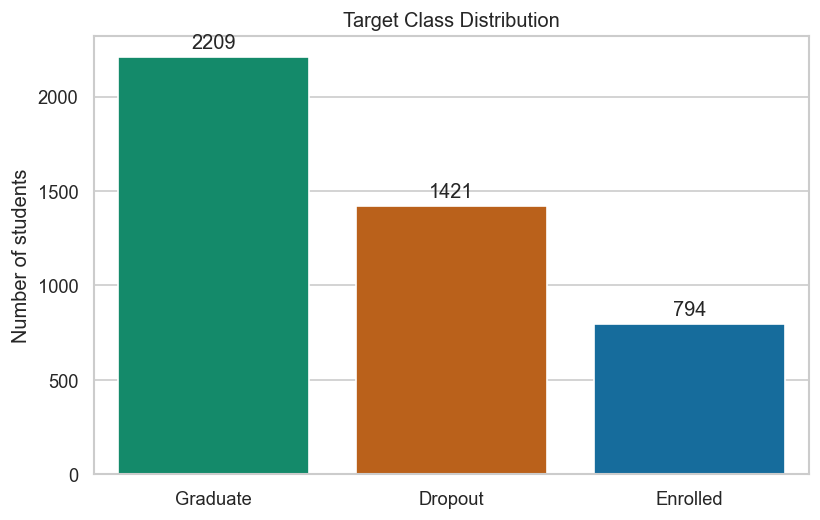

Missing values in processed data: 0


In [4]:
eda_palette = {
    "Dropout": "#d55e00",
    "Enrolled": "#0072b2",
    "Graduate": "#009e73",
}

target_counts = (
    df["Target Label"]
    .value_counts()
    .rename_axis("Target")
    .reset_index(name="Count")
)
target_counts["Percent"] = target_counts["Count"] / len(df) * 100

display(target_counts.style.format({"Percent": "{:.2f}%"}))

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(
    data=target_counts,
    x="Target",
    y="Count",
    hue="Target",
    hue_order=["Dropout", "Enrolled", "Graduate"],
    palette=eda_palette,
    legend=False,
    ax=ax,
)
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)
ax.set_title("Target Class Distribution")
ax.set_xlabel("")
ax.set_ylabel("Number of students")
plt.tight_layout()
plt.show()

missing_summary = df.drop(columns=["Target Label"]).isna().sum().sort_values(ascending=False)
print("Missing values in processed data:", int(missing_summary.sum()))


### 3.1 Feature-Target Relationship

The most interpretable features are inspected by target class before applying dimensionality reduction. Academic performance variables are expected to be especially informative because they directly summarize first- and second-semester progress.


,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),Curricular units 1st sem (grade),Curricular units 2nd sem (grade),Age at enrollment
Target Label,,,,,
Dropout,2.55,1.94,7.26,5.90,26.07
Enrolled,4.32,4.06,11.13,11.12,22.37
Graduate,6.23,6.18,12.64,12.70,21.78


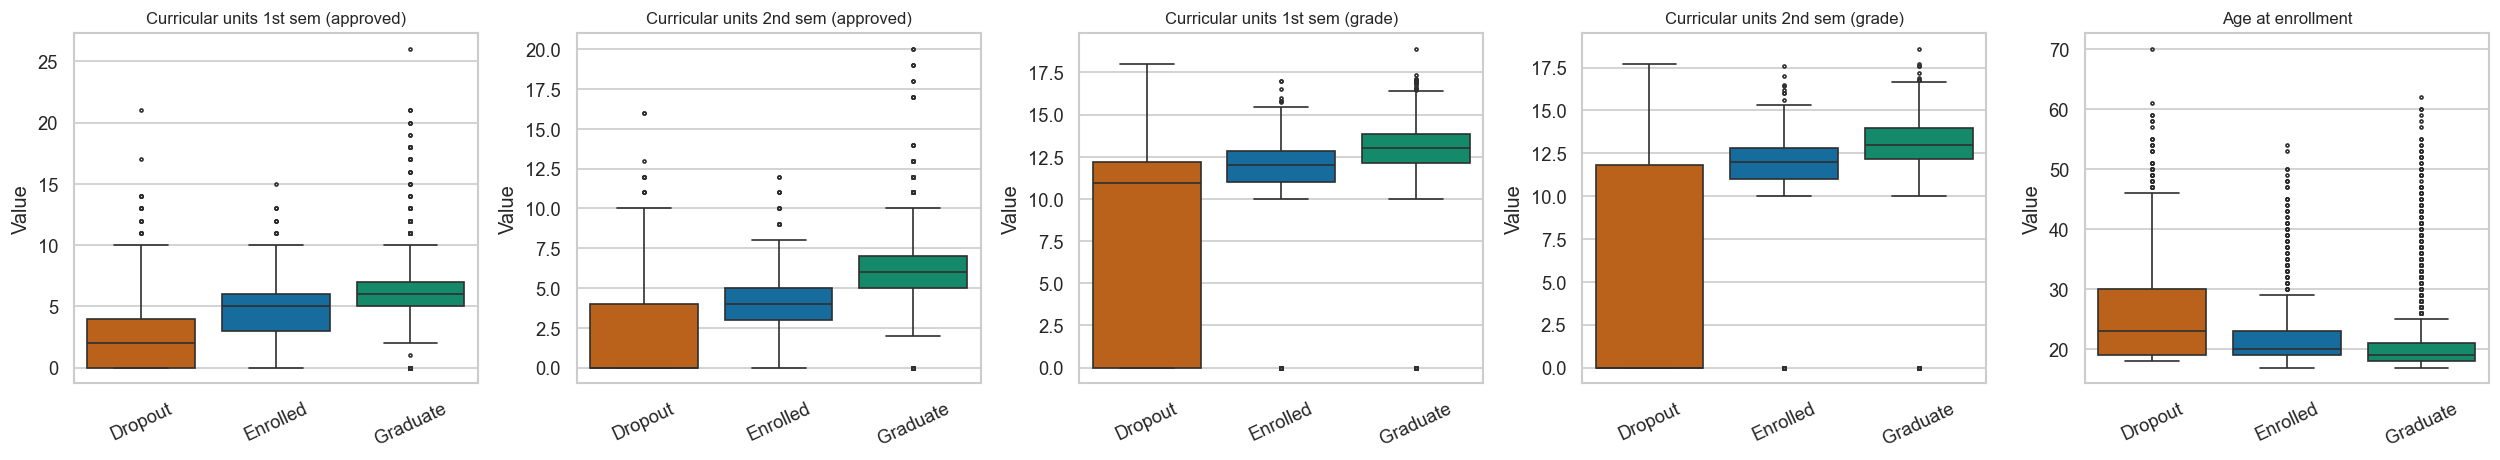

,Tuition fees up to date,Debtor,Scholarship holder,Gender
Target Label,,,,
Dropout,0.678,0.220,0.094,0.493
Enrolled,0.947,0.113,0.164,0.387
Graduate,0.987,0.046,0.378,0.248


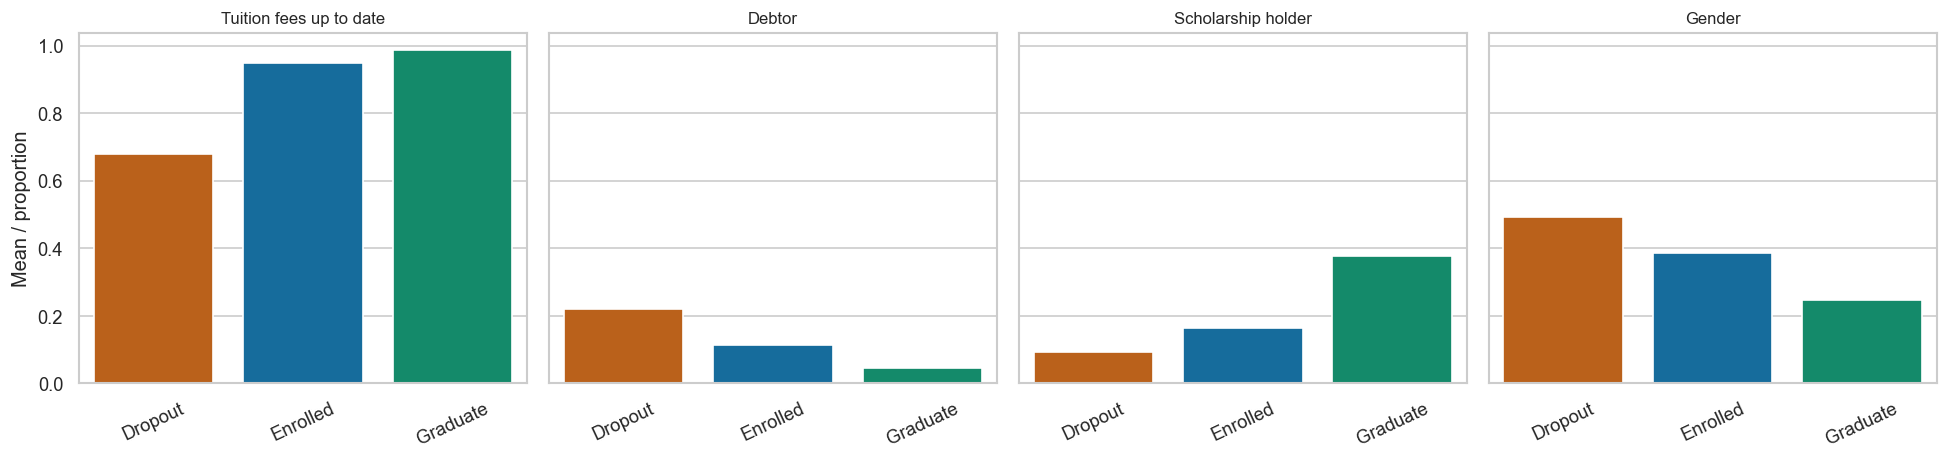

In [5]:
performance_features = [
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)",
    "Age at enrollment",
]
performance_features = [col for col in performance_features if col in df.columns]

profile_summary = (
    df.groupby("Target Label")[performance_features]
    .mean()
    .reindex(["Dropout", "Enrolled", "Graduate"])
)
display(profile_summary.round(2))

plot_df = df.melt(
    id_vars="Target Label",
    value_vars=performance_features,
    var_name="Feature",
    value_name="Value",
)
fig, axes = plt.subplots(1, len(performance_features), figsize=(4.2 * len(performance_features), 4), sharey=False)
if len(performance_features) == 1:
    axes = [axes]
for ax, feature in zip(axes, performance_features):
    sns.boxplot(
        data=plot_df[plot_df["Feature"] == feature],
        x="Target Label",
        y="Value",
        hue="Target Label",
        order=["Dropout", "Enrolled", "Graduate"],
        palette=eda_palette,
        legend=False,
        ax=ax,
        fliersize=1.8,
    )
    ax.set_title(feature, fontsize=10)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

binary_features = [
    "Tuition fees up to date",
    "Debtor",
    "Scholarship holder",
    "Gender",
]
binary_features = [col for col in binary_features if col in df.columns]
binary_rates = (
    df.groupby("Target Label")[binary_features]
    .mean()
    .reindex(["Dropout", "Enrolled", "Graduate"])
)
display(binary_rates.round(3))

fig, axes = plt.subplots(1, len(binary_features), figsize=(4.1 * len(binary_features), 4), sharey=True)
if len(binary_features) == 1:
    axes = [axes]
for ax, feature in zip(axes, binary_features):
    sns.barplot(
        data=df,
        x="Target Label",
        y=feature,
        hue="Target Label",
        order=["Dropout", "Enrolled", "Graduate"],
        palette=eda_palette,
        legend=False,
        errorbar=None,
        ax=ax,
    )
    ax.set_title(feature, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Mean / proportion")
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


### 3.2 Academic Performance Block Redundancy

Before compressing features, we first check whether the academic performance variables contain repeated information. The first- and second-semester curricular-unit measures are expected to describe related student progress, so high pairwise correlations would justify using compact feature engineering rather than listing every semester-specific variable separately.


,Feature 1,Feature 2,Abs correlation
0,Curricular units 1st sem (credited),Curricular units 2nd sem (credited),0.9448
1,Curricular units 1st sem (enrolled),Curricular units 2nd sem (enrolled),0.9426
2,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),0.9040
3,Curricular units 1st sem (grade),Curricular units 2nd sem (grade),0.8372
4,Curricular units 1st sem (evaluations),Curricular units 2nd sem (evaluations),0.7789
5,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),0.7743
6,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),0.7691
7,Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),0.7608
8,Curricular units 2nd sem (credited),Curricular units 1st sem (enrolled),0.7537
9,Curricular units 2nd sem (enrolled),Curricular units 1st sem (approved),0.7338


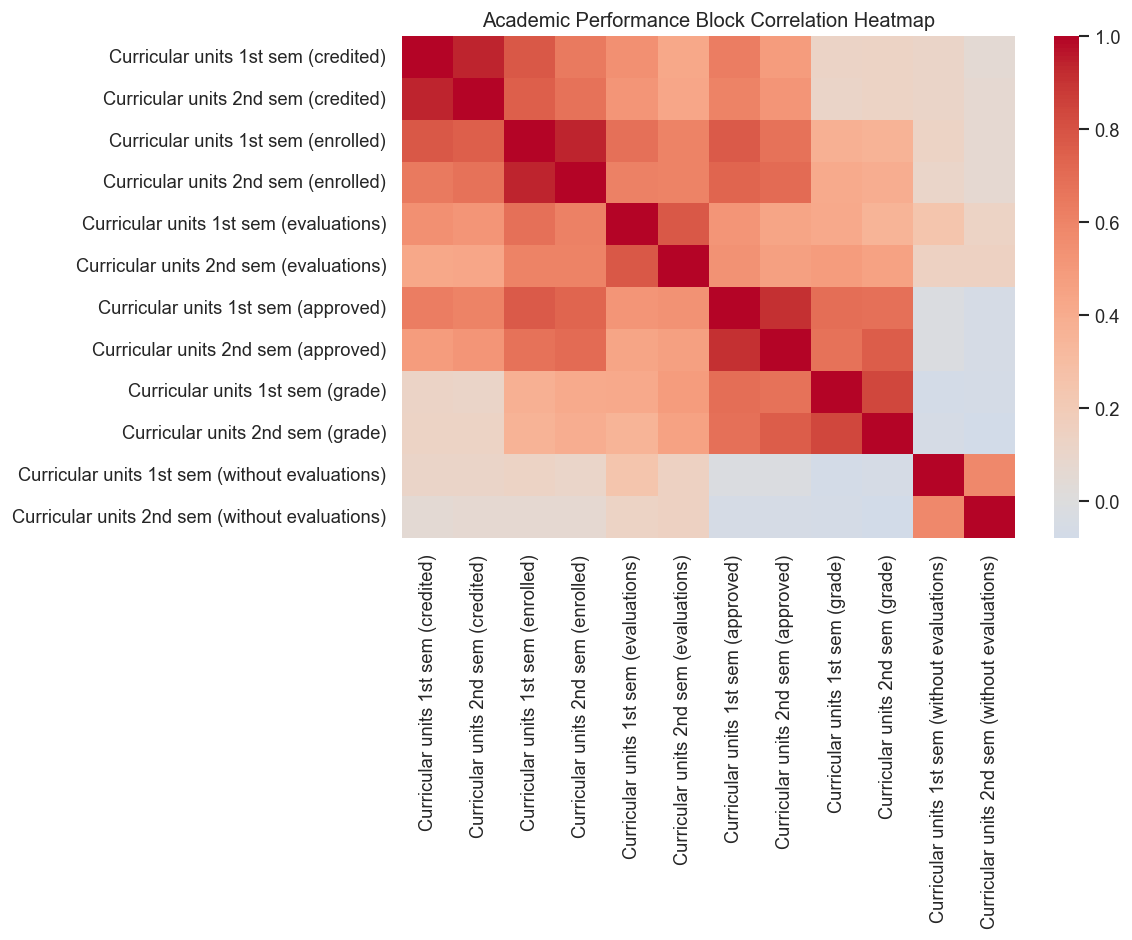

In [17]:
academic_block_features = [
    "Curricular units 1st sem (credited)",
    "Curricular units 2nd sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 2nd sem (evaluations)",
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 1st sem (without evaluations)",
    "Curricular units 2nd sem (without evaluations)",
]
academic_block_features = [col for col in academic_block_features if col in df.columns]

academic_corr = df[academic_block_features].corr(numeric_only=True)
academic_pair_rows = []
for i, feature_a in enumerate(academic_block_features):
    for feature_b in academic_block_features[i + 1:]:
        academic_pair_rows.append(
            {
                "Feature 1": feature_a,
                "Feature 2": feature_b,
                "Abs correlation": abs(academic_corr.loc[feature_a, feature_b]),
            }
        )

top_academic_pairwise_corr = (
    pd.DataFrame(academic_pair_rows)
    .sort_values("Abs correlation", ascending=False)
    .head(12)
    .reset_index(drop=True)
)
display(top_academic_pairwise_corr.round(4))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    academic_corr,
    cmap="coolwarm",
    center=0,
    ax=ax,
)
ax.set_title("Academic Performance Block Correlation Heatmap")
plt.tight_layout()
plt.show()



### 3.3 Compact Average-Based Feature Screening

The first compression method is an interpretable average-based summary. Paired first- and second-semester curricular-unit features are averaged into composite variables before computing correlation with the encoded target. This keeps the correlation ranking readable and highlights feature families such as average approved units and average grades, but it is still only an exploratory screening tool rather than causal evidence.


,Correlation with Target
Average curricular units approved,0.5904
Average curricular units grade,0.5504
Tuition fees up to date,0.4098
Scholarship holder,0.2976
Age at enrollment,-0.2434
Debtor,-0.2410
Gender,-0.2293
Application mode,-0.2217
Average curricular units enrolled,0.1677
Admission grade,0.1209


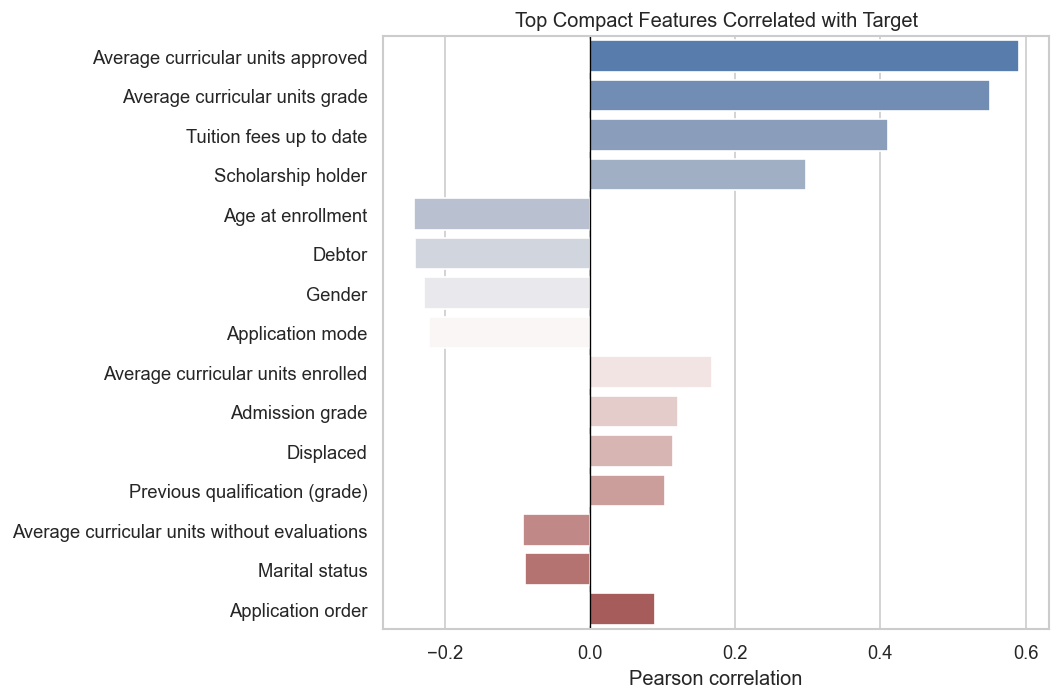

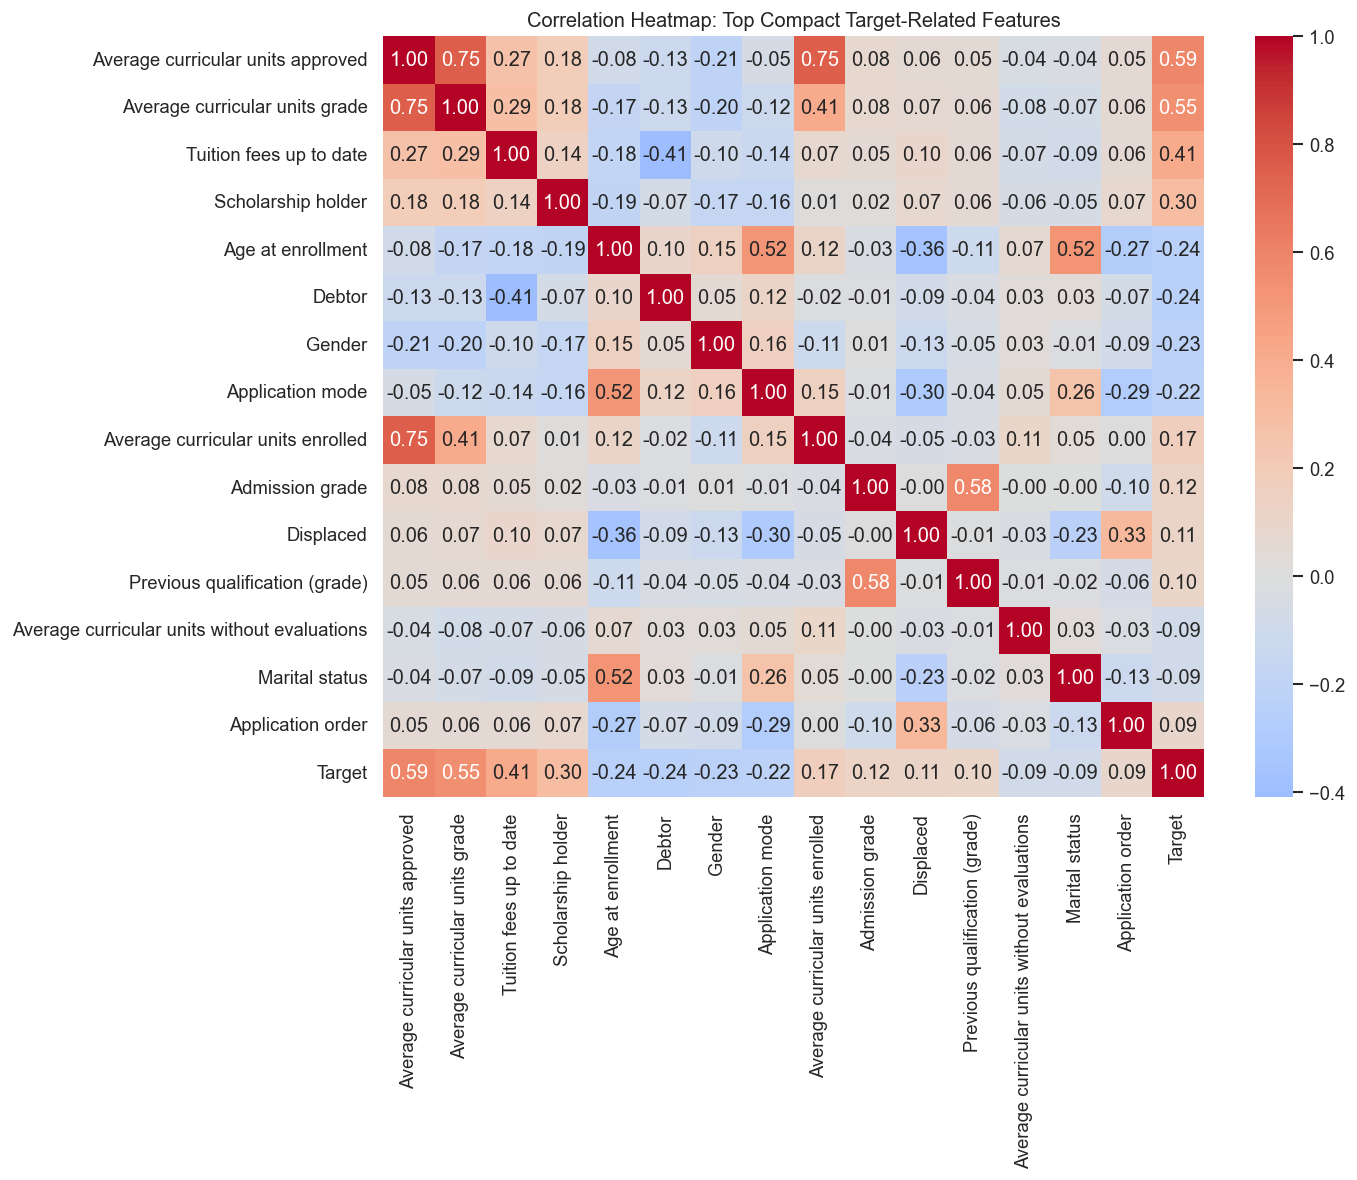

In [16]:
semester_feature_pairs = {
    "Average curricular units approved": [
        "Curricular units 1st sem (approved)",
        "Curricular units 2nd sem (approved)",
    ],
    "Average curricular units grade": [
        "Curricular units 1st sem (grade)",
        "Curricular units 2nd sem (grade)",
    ],
    "Average curricular units enrolled": [
        "Curricular units 1st sem (enrolled)",
        "Curricular units 2nd sem (enrolled)",
    ],
    "Average curricular units evaluations": [
        "Curricular units 1st sem (evaluations)",
        "Curricular units 2nd sem (evaluations)",
    ],
    "Average curricular units credited": [
        "Curricular units 1st sem (credited)",
        "Curricular units 2nd sem (credited)",
    ],
    "Average curricular units without evaluations": [
        "Curricular units 1st sem (without evaluations)",
        "Curricular units 2nd sem (without evaluations)",
    ],
}

compact_corr_df = df.drop(columns=["Target Label"]).copy()
paired_semester_columns = set()

for composite_name, source_columns in semester_feature_pairs.items():
    available_columns = [col for col in source_columns if col in compact_corr_df.columns]
    if available_columns:
        compact_corr_df[composite_name] = compact_corr_df[available_columns].mean(axis=1)
        paired_semester_columns.update(available_columns)

compact_corr_df = compact_corr_df.drop(columns=sorted(paired_semester_columns))

compact_corr_matrix = compact_corr_df.corr(numeric_only=True)
compact_target_corr = (
    compact_corr_matrix["Target"]
    .drop("Target")
    .sort_values(key=lambda values: values.abs(), ascending=False)
)
top_compact_target_corr = compact_target_corr.head(15).rename("Correlation with Target").to_frame()
display(top_compact_target_corr.round(4))

fig, ax = plt.subplots(figsize=(9, 6))
plot_corr = top_compact_target_corr.reset_index().rename(columns={"index": "Feature"})
sns.barplot(
    data=plot_corr,
    y="Feature",
    x="Correlation with Target",
    hue="Feature",
    palette="vlag",
    legend=False,
    ax=ax,
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Top Compact Features Correlated with Target")
ax.set_xlabel("Pearson correlation")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

heatmap_features = top_compact_target_corr.index.tolist() + ["Target"]
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    compact_corr_df[heatmap_features].corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    ax=ax,
)
ax.set_title("Correlation Heatmap: Top Compact Target-Related Features")
plt.tight_layout()
plt.show()


### 3.4 PCA-Based Academic Feature Compression

The second compression method is PCA on the academic performance block. Unlike simple averages, PCA creates orthogonal components that can preserve multiple directions of academic-performance variation. This makes it more suitable as a downstream modeling candidate when multicollinearity is a concern. If PCA features are later used in supervised models, PCA should be fitted on the training split and then applied to validation/test data to avoid data leakage.


,Component,Explained variance ratio,Cumulative explained variance
0,Academic_PC1,0.5138,0.5138
1,Academic_PC2,0.1698,0.6836
2,Academic_PC3,0.1227,0.8063
3,Academic_PC4,0.0668,0.8730
4,Academic_PC5,0.0358,0.9088
5,Academic_PC6,0.0343,0.9431


,Correlation with Target
Academic_PC1,0.3458
Academic_PC2,0.4625
Academic_PC3,0.1212
Academic_PC4,-0.3525
Academic_PC5,0.0683
Academic_PC6,-0.0470


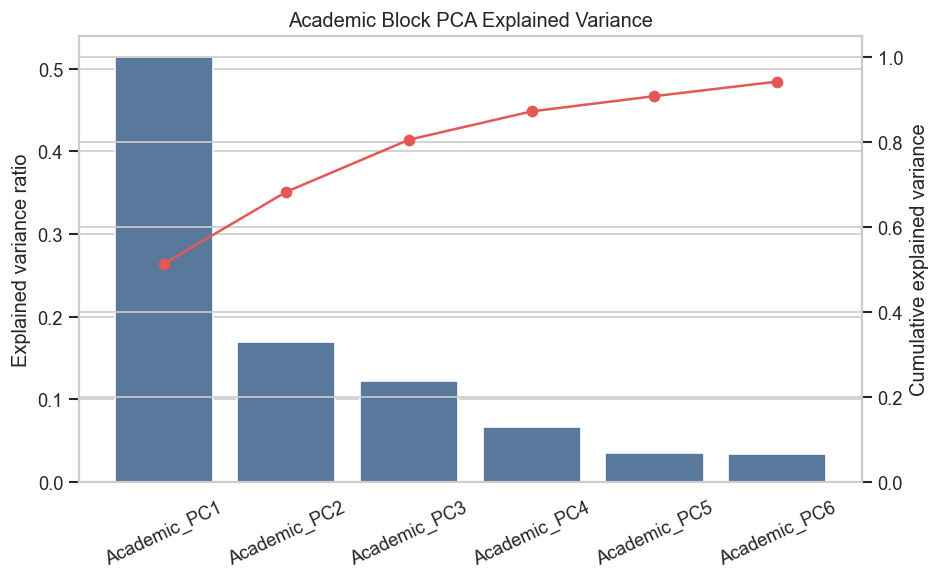

In [18]:
academic_block_filled = df[academic_block_features].fillna(df[academic_block_features].median())
academic_block_scaled = StandardScaler().fit_transform(academic_block_filled)
academic_pca = PCA(n_components=min(6, len(academic_block_features)), random_state=RANDOM_STATE)
academic_pca_scores = academic_pca.fit_transform(academic_block_scaled)
academic_pca_df = pd.DataFrame(
    academic_pca_scores,
    columns=[f"Academic_PC{i + 1}" for i in range(academic_pca_scores.shape[1])],
)
academic_pca_df["Target"] = df["Target"].values


academic_pca_variance = pd.DataFrame(
    {
        "Component": [f"Academic_PC{i + 1}" for i in range(len(academic_pca.explained_variance_ratio_))],
        "Explained variance ratio": academic_pca.explained_variance_ratio_,
        "Cumulative explained variance": academic_pca.explained_variance_ratio_.cumsum(),
    }
)
display(academic_pca_variance.round(4))

academic_pc_target_corr = (
    academic_pca_df.corr(numeric_only=True)["Target"]
    .drop("Target")
    .rename("Correlation with Target")
    .to_frame()
)
display(academic_pc_target_corr.round(4))

fig, ax1 = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=academic_pca_variance,
    x="Component",
    y="Explained variance ratio",
    color="#4C78A8",
    ax=ax1,
)
ax1.set_title("Academic Block PCA Explained Variance")
ax1.set_xlabel("")
ax1.set_ylabel("Explained variance ratio")
ax1.tick_params(axis="x", rotation=25)
ax2 = ax1.twinx()
ax2.plot(
    academic_pca_variance["Component"],
    academic_pca_variance["Cumulative explained variance"],
    color="#E45756",
    marker="o",
)
ax2.set_ylabel("Cumulative explained variance")
ax2.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()


## 4. Prepare Features for t-SNE

`Target` is excluded from the input features and used only for coloring the plots. The dataset contains both encoded categorical variables and continuous numeric variables. For a more rigorous distance-based visualization, categorical variables are one-hot encoded while continuous and ordinal numeric variables are standardized.


In [19]:
feature_cols = [col for col in df.columns if col not in ["Target", "Target Label"]]
X = df[feature_cols].copy()
y = df["Target"].copy()
y_label = df["Target Label"].copy()

# These columns are integer-coded categories in the original dataset, not continuous quantities.
categorical_feature_cols = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International",
]
categorical_feature_cols = [col for col in categorical_feature_cols if col in X.columns]
numeric_feature_cols = [col for col in X.columns if col not in categorical_feature_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_feature_cols),
        ("numeric", StandardScaler(), numeric_feature_cols),
    ],
    verbose_feature_names_out=False,
)

X_prepared = preprocessor.fit_transform(X)

print(f"Number of samples: {X_prepared.shape[0]}")
print(f"Original input features before encoding: {len(feature_cols)}")
print(f"t-SNE input features after one-hot encoding and scaling: {X_prepared.shape[1]}")
print("Categorical features one-hot encoded:", len(categorical_feature_cols))
print("Numeric/ordinal features standardized:", len(numeric_feature_cols))
print("Target excluded from feature matrix:", "Target" not in feature_cols)

Number of samples: 4424
Original input features before encoding: 36
t-SNE input features after one-hot encoding and scaling: 255
Categorical features one-hot encoded: 17
Numeric/ordinal features standardized: 19
Target excluded from feature matrix: True


## 5. Helper Plotting Functions


In [11]:
palette = {
    "Dropout": "#d55e00",
    "Enrolled": "#0072b2",
    "Graduate": "#009e73",
}

def make_tsne(n_components=2, perplexity=30):
    model = TSNE(
        n_components=n_components,
        perplexity=perplexity,
        learning_rate="auto",
        init="pca",
        random_state=RANDOM_STATE,
    )
    return model.fit_transform(X_prepared)

def embedding_frame(embedding, prefix="TSNE"):
    data = pd.DataFrame(embedding, columns=[f"{prefix}{i + 1}" for i in range(embedding.shape[1])])
    data["Target"] = y.values
    data["Target Label"] = y_label.values
    return data

def plot_tsne_2d(data, title, ax=None, legend=True):
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))
    sns.scatterplot(
        data=data,
        x="TSNE1",
        y="TSNE2",
        hue="Target Label",
        hue_order=["Dropout", "Enrolled", "Graduate"],
        palette=palette,
        s=18,
        alpha=0.75,
        linewidth=0,
        ax=ax,
        legend=legend,
    )
    ax.set_title(title)
    ax.set_xlabel("t-SNE dimension 1")
    ax.set_ylabel("t-SNE dimension 2")
    if legend:
        ax.legend(title="Target", loc="best", frameon=True)
    return ax

def knn_label_agreement(points, labels, n_neighbors=15):
    neighbors = NearestNeighbors(n_neighbors=n_neighbors + 1).fit(points)
    neighbor_indices = neighbors.kneighbors(return_distance=False)[:, 1:]
    return (labels[neighbor_indices] == labels[:, None]).mean()

def random_same_label_baseline(labels):
    proportions = pd.Series(labels).value_counts(normalize=True)
    return float((proportions ** 2).sum())

def evaluate_embedding(name, embedding, n_neighbors=15):
    labels = y.to_numpy()
    return {
        "Embedding": name,
        "Dimensions": embedding.shape[1],
        "Silhouette by Target": silhouette_score(embedding, labels),
        "Davies-Bouldin by Target": davies_bouldin_score(embedding, labels),
        f"Trustworthiness@{n_neighbors}": trustworthiness(X_prepared, embedding, n_neighbors=n_neighbors),
        f"KNN Label Agreement@{n_neighbors}": knn_label_agreement(embedding, labels, n_neighbors=n_neighbors),
    }

## 6. PCA Baseline Projection

PCA is added as a linear baseline before t-SNE. If PCA already separates the classes clearly, the dominant structure is mostly linear. If PCA is mixed while t-SNE shows local grouping, the useful structure is more local or nonlinear.


PCA explained variance: PC1=0.234, PC2=0.097, total=0.331


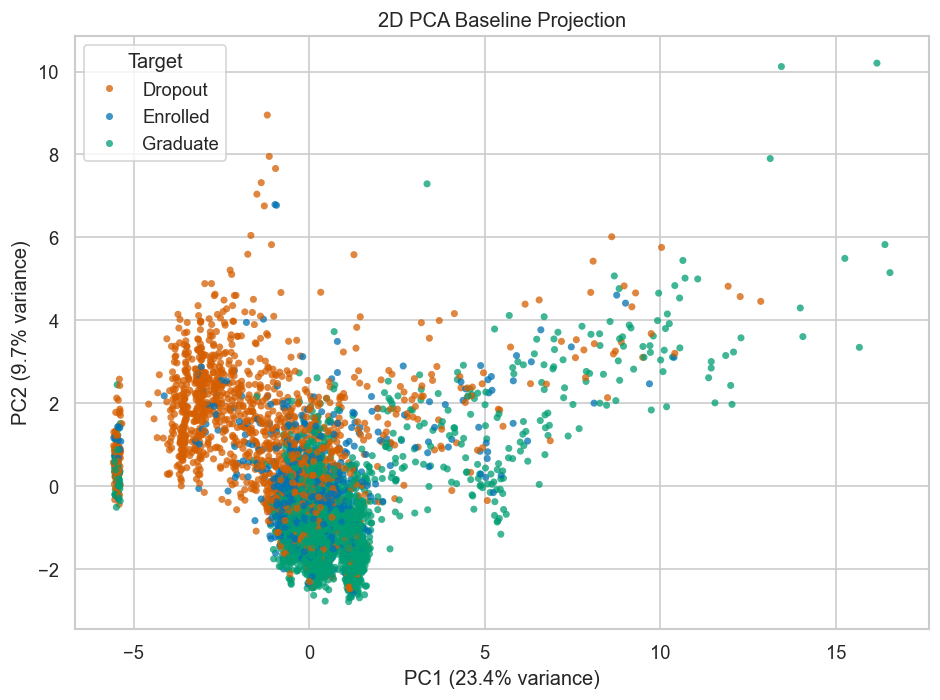

,Embedding,Dimensions,Silhouette by Target,Davies-Bouldin by Target,Trustworthiness@15,KNN Label Agreement@15
0,2D PCA baseline,2,0.0032,2.9621,0.8021,0.5872


In [12]:
pca_model = PCA(n_components=2, random_state=RANDOM_STATE)
pca_2d = pca_model.fit_transform(X_prepared)
pca_df = pd.DataFrame(pca_2d, columns=["PC1", "PC2"])
pca_df["Target"] = y.values
pca_df["Target Label"] = y_label.values

explained = pca_model.explained_variance_ratio_
print(f"PCA explained variance: PC1={explained[0]:.3f}, PC2={explained[1]:.3f}, total={explained.sum():.3f}")

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Target Label",
    hue_order=["Dropout", "Enrolled", "Graduate"],
    palette=palette,
    s=18,
    alpha=0.75,
    linewidth=0,
    ax=ax,
)
ax.set_title("2D PCA Baseline Projection")
ax.set_xlabel(f"PC1 ({explained[0] * 100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({explained[1] * 100:.1f}% variance)")
ax.legend(title="Target", loc="best", frameon=True)
plt.tight_layout()
plt.show()

pca_metrics = evaluate_embedding("2D PCA baseline", pca_2d, n_neighbors=15)
display(pd.DataFrame([pca_metrics]).round(4))


## 7. Main 2D t-SNE Projection

`perplexity=30` is used as the main setting because it balances local and broader neighborhood structure for a dataset of this size.


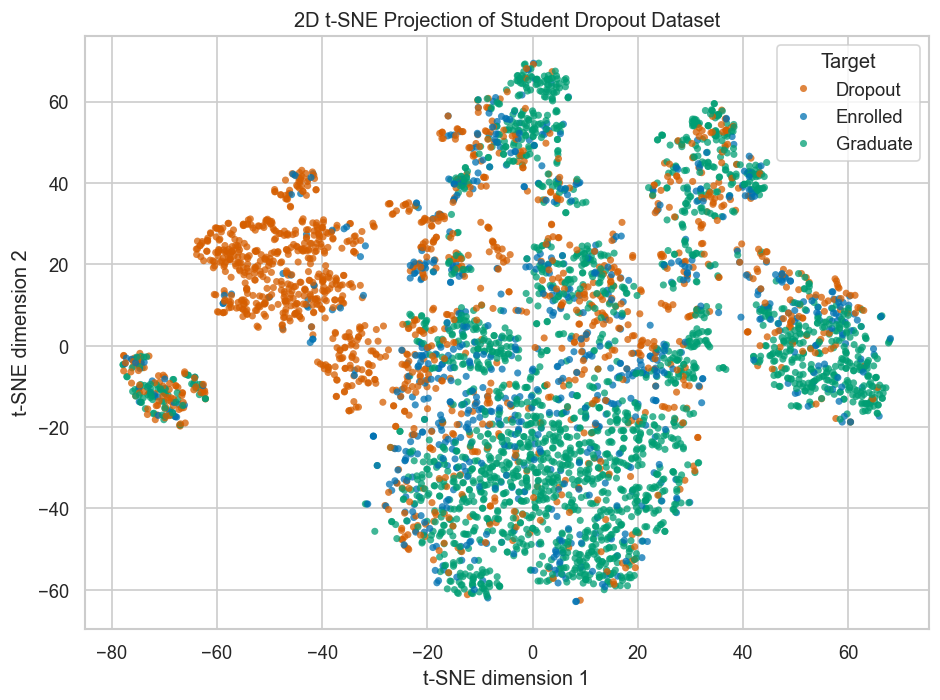

,TSNE1,TSNE2,Target,Target Label
0,-66.330284,-15.248606,0,Dropout
1,17.138304,-25.326008,2,Graduate
2,-61.820347,25.936541,0,Dropout
3,-5.099010,53.054626,2,Graduate
4,7.804188,21.547667,2,Graduate


In [13]:
tsne_2d = make_tsne(n_components=2, perplexity=30)
tsne_2d_df = embedding_frame(tsne_2d)

fig, ax = plt.subplots(figsize=(8, 6))
plot_tsne_2d(tsne_2d_df, "2D t-SNE Projection of Student Dropout Dataset", ax=ax)
plt.tight_layout()
plt.show()

display(tsne_2d_df.head())

## 8. 3D t-SNE Projection

The 3D view provides an additional perspective on local class separation. It should be used as supporting evidence rather than a replacement for quantitative model evaluation.


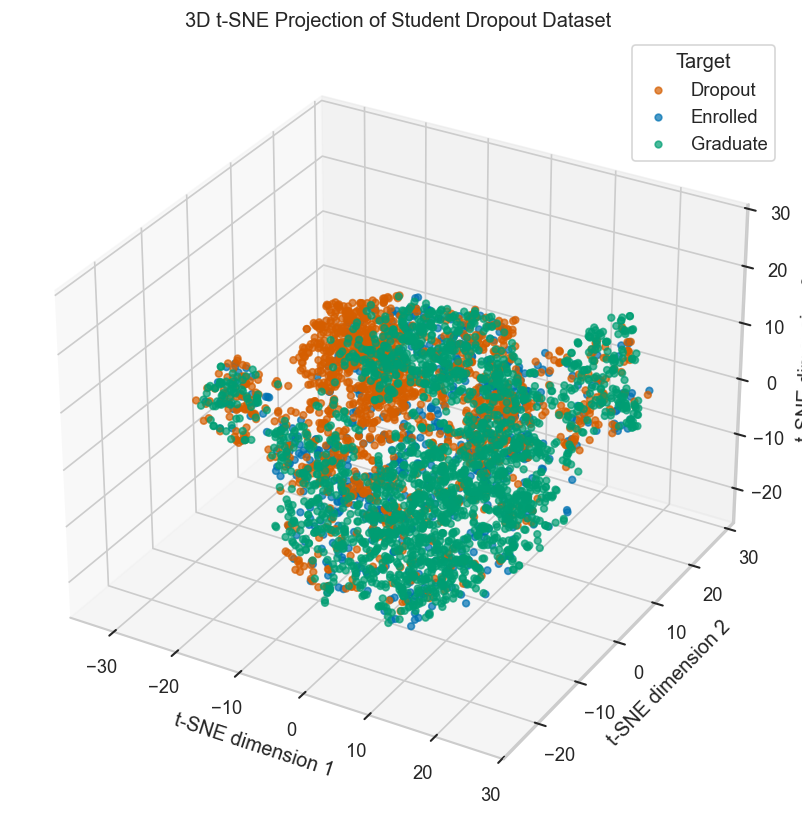

In [14]:
tsne_3d = make_tsne(n_components=3, perplexity=30)
tsne_3d_df = embedding_frame(tsne_3d)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

for label in ["Dropout", "Enrolled", "Graduate"]:
    subset = tsne_3d_df[tsne_3d_df["Target Label"] == label]
    ax.scatter(
        subset["TSNE1"],
        subset["TSNE2"],
        subset["TSNE3"],
        label=label,
        s=16,
        alpha=0.7,
        color=palette[label],
    )

ax.set_title("3D t-SNE Projection of Student Dropout Dataset")
ax.set_xlabel("t-SNE dimension 1")
ax.set_ylabel("t-SNE dimension 2")
ax.set_zlabel("t-SNE dimension 3")
ax.legend(title="Target", loc="best")
plt.tight_layout()
plt.show()

## 9. Perplexity Sensitivity Analysis

Perplexity controls the effective number of neighbors used by t-SNE. Lower values emphasize very local structure; higher values incorporate broader neighborhood information. The visual pattern should be checked under multiple settings before drawing conclusions.


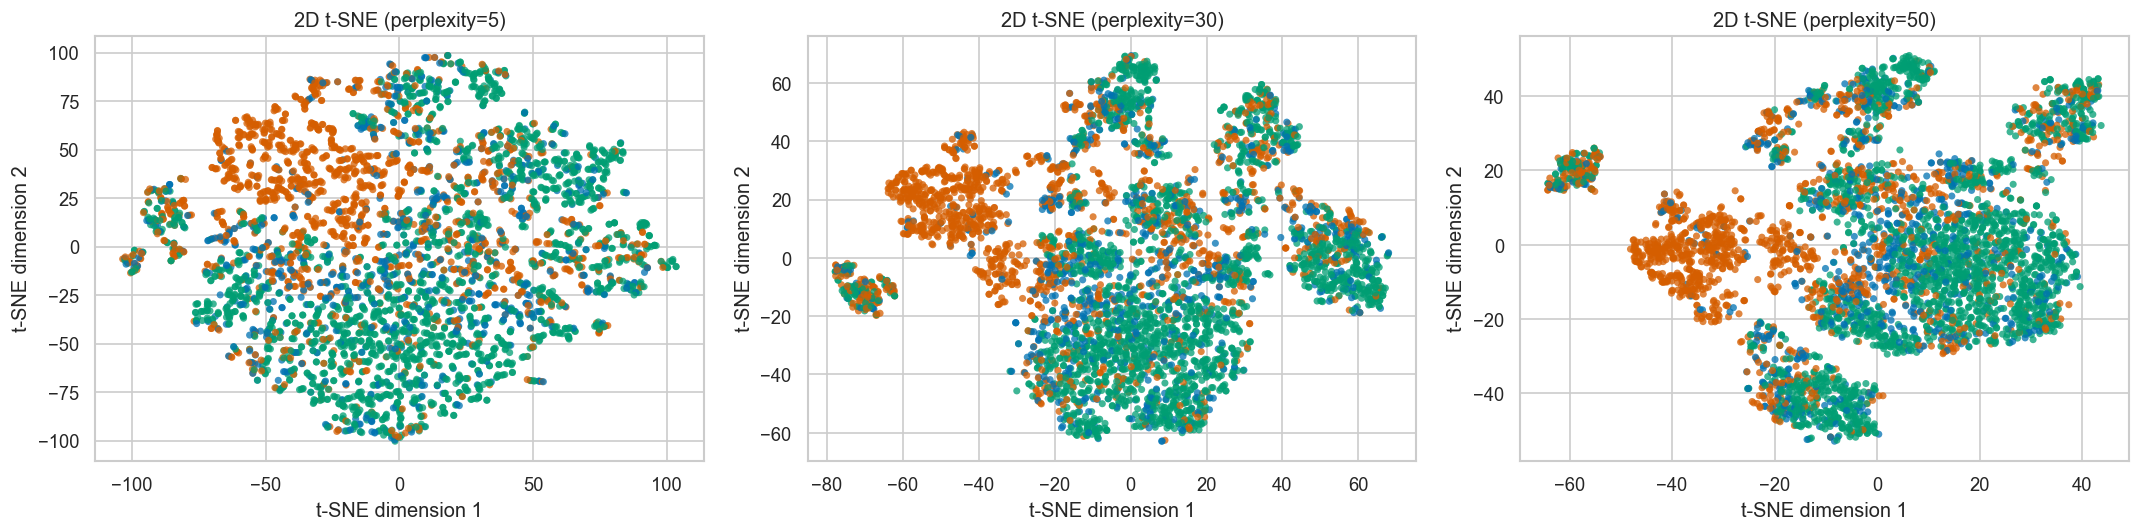

In [14]:
perplexities = [5, 30, 50]
tsne_embeddings_2d = {30: tsne_2d}

fig, axes = plt.subplots(1, len(perplexities), figsize=(18, 5), sharex=False, sharey=False)

for ax, perplexity in zip(axes, perplexities):
    if perplexity not in tsne_embeddings_2d:
        tsne_embeddings_2d[perplexity] = make_tsne(n_components=2, perplexity=perplexity)
    embedding = tsne_embeddings_2d[perplexity]
    data = embedding_frame(embedding)
    plot_tsne_2d(
        data,
        title=f"2D t-SNE (perplexity={perplexity})",
        ax=ax,
        legend=False,
    )

handles, labels = axes[-1].get_legend_handles_labels()
if handles:
    fig.legend(handles, labels, title="Target", loc="upper center", ncol=3, frameon=True)

plt.tight_layout(rect=[0, 0, 1, 0.92])
plt.show()

## 10. Auxiliary Quality Metrics

These metrics do not replace visual inspection, but they make the interpretation more rigorous.

- `Trustworthiness`: how well local neighborhoods from the high-dimensional data are preserved in the embedding. Higher is better.
- `Silhouette by Target`: how separated the target classes are in the embedding. Values near 0 indicate overlapping classes.
- `Davies-Bouldin by Target`: another class-separation metric. Lower is better.
- `KNN Label Agreement`: the fraction of nearest neighbors in the embedding that share the same target label. Compare it with the random same-label baseline.


In [8]:
N_NEIGHBORS = 15
metrics_rows = []

for perplexity in perplexities:
    metrics_rows.append(
        evaluate_embedding(
            name=f"2D t-SNE perplexity={perplexity}",
            embedding=tsne_embeddings_2d[perplexity],
            n_neighbors=N_NEIGHBORS,
        )
    )

metrics_rows.append(
    evaluate_embedding(
        name="3D t-SNE perplexity=30",
        embedding=tsne_3d,
        n_neighbors=N_NEIGHBORS,
    )
)

metrics_df = pd.DataFrame(metrics_rows)

baseline_df = pd.DataFrame(
    {
        "Metric": [
            f"Prepared-space KNN Label Agreement@{N_NEIGHBORS}",
            "Random Same-Label Baseline",
        ],
        "Value": [
            knn_label_agreement(X_prepared, y.to_numpy(), n_neighbors=N_NEIGHBORS),
            random_same_label_baseline(y.to_numpy()),
        ],
    }
)

display(metrics_df.round(4))
display(baseline_df.round(4))

,Embedding,Dimensions,Silhouette by Target,Davies-Bouldin by Target,Trustworthiness@15,KNN Label Agreement@15
0,2D t-SNE perplexity=5,2,0.0029,6.8985,0.9566,0.5780
1,2D t-SNE perplexity=30,2,0.0157,5.9721,0.9714,0.5844
2,2D t-SNE perplexity=50,2,0.0222,5.5304,0.9730,0.5919
3,3D t-SNE perplexity=30,3,0.0234,6.2471,0.9789,0.5928


,Metric,Value
0,Prepared-space KNN Label Agreement@15,0.6174
1,Random Same-Label Baseline,0.3847


## 11. Discussion

The t-SNE visualization should be interpreted as a local-neighborhood map of students with similar enrollment, demographic, socioeconomic, and semester-performance characteristics. If `Graduate` points form visibly dense regions, this suggests that successful students share similar feature profiles in the prepared input space. If `Dropout` and `Enrolled` points overlap with other classes, this indicates that their profiles are less cleanly separated by visualization alone and may require supervised models or additional feature engineering for stronger discrimination.

The auxiliary metrics should be interpreted together with the plots. High trustworthiness supports that the embedding preserves local neighborhoods. However, near-zero silhouette scores or high Davies-Bouldin scores would indicate that the target classes are still substantially overlapping in the t-SNE space. The perplexity comparison is part of the interpretation. Stable class patterns across `perplexity=5`, `30`, and `50` are more credible than patterns that appear only under one setting. Following the lecture guidance, cluster sizes and long-range distances between clusters should not be treated as direct evidence of class frequency or between-class dissimilarity.


The exploratory findings show moderate class imbalance: `Graduate` is the largest group, while `Enrolled` is the smallest. This should be considered when visually inspecting scatter plots, since a denser visible region can partly reflect class frequency rather than stronger separability. The strongest target-related variables are academic performance and progression features, especially approved curricular units and semester grades. Financial and administrative indicators such as tuition-fee status, debtor status, scholarship holder status, and age at enrollment also show class-level differences.

The PCA baseline provides a linear comparison point. If PCA explains only a limited share of variance and still shows overlapping classes, this supports using t-SNE as a local-neighborhood visualization rather than expecting a globally clean linear separation. However, even when t-SNE shows local grouping, the overlap between `Dropout`, `Enrolled`, and `Graduate` should be treated as evidence that visualization alone is not sufficient for classification.
